# Clustering fournisseurs

Objectif : regrouper les fournisseurs selon leur performance (qualité, volume, diversité produit) pour identifier des profils (fiable / moyen / à risque).

Features utilisées : `avg_reject_rate`, `avg_receipt_rate`, `avg_order_qty`, `product_diversity`.
Filtre appliqué : fournisseurs avec au moins 30 commandes (sinon les taux sont peu fiables statistiquement).

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

pd.set_option("display.max_columns", None)

## 1. Chargement des données depuis SQLite

In [2]:
conn = sqlite3.connect("../database/adventureworks.db")

query = """
SELECT
    poh.vendorid,
    COUNT(*) AS total_orders,
    AVG(CAST(pod.rejectedqty AS FLOAT) / pod.orderqty) AS avg_reject_rate,
    AVG(CAST(pod.receivedqty AS FLOAT) / pod.orderqty) AS avg_receipt_rate,
    AVG(pod.orderqty) AS avg_order_qty,
    COUNT(DISTINCT pod.productid) AS product_diversity
FROM purchaseorderdetail pod
LEFT JOIN purchaseorderheader poh
    ON pod.purchaseorderid = poh.purchaseorderid
WHERE pod.orderqty > 0
GROUP BY poh.vendorid
HAVING COUNT(*) >= 30
ORDER BY avg_reject_rate DESC
"""

vendor_df = pd.read_sql(query, conn)
conn.close()

print(vendor_df.shape)
vendor_df.head()

(79, 6)


,vendorid,total_orders,avg_reject_rate,avg_receipt_rate,avg_order_qty,product_diversity
0,1510,51,0.058824,1.000000,3.0,1
1,1664,51,0.053832,0.982460,550.0,1
2,1588,100,0.053455,0.990091,550.0,2
3,1560,102,0.052888,0.992228,550.0,2
4,1658,102,0.052888,0.991747,550.0,2


## 2. Standardisation

In [3]:
feature_cols = ["avg_reject_rate", "avg_receipt_rate", "avg_order_qty", "product_diversity"]
X = vendor_df[feature_cols]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pd.DataFrame(X_scaled, columns=feature_cols).describe()

,avg_reject_rate,avg_receipt_rate,avg_order_qty,product_diversity
count,7.900000e+01,7.900000e+01,7.900000e+01,7.900000e+01
mean,-3.372829e-17,7.684430e-15,-1.686415e-17,4.497106e-17
std,1.006390e+00,1.006390e+00,1.006390e+00,1.006390e+00
min,-1.621147e+00,-2.364370e+00,-1.026555e+00,-6.199723e-01
25%,-8.949319e-01,-6.848097e-01,-1.026555e+00,-6.199723e-01
50%,-7.404772e-02,-3.853900e-02,8.858818e-01,-4.701931e-01
75%,5.818880e-01,1.112727e+00,8.858818e-01,-9.574496e-02
max,2.084321e+00,1.112727e+00,3.333242e+00,3.723626e+00


## 3. Méthode du coude (choix de K)

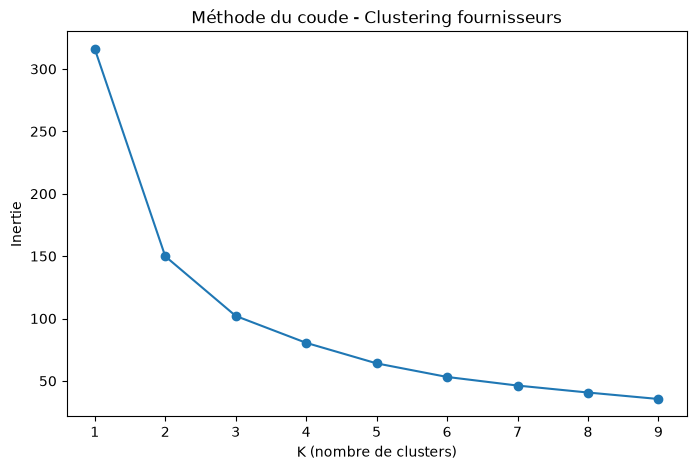

In [4]:
import os
os.makedirs("outputs", exist_ok=True)

inertias = []
k_range = range(1, 10)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_range, inertias, marker="o")
plt.xlabel("K (nombre de clusters)")
plt.ylabel("Inertie")
plt.title("Méthode du coude - Clustering fournisseurs")
plt.savefig("outputs/elbow_fournisseur.png")
plt.show()

In [5]:
K_CHOISI = 3  

kmeans = KMeans(n_clusters=K_CHOISI, random_state=42, n_init=10)
vendor_df["cluster"] = kmeans.fit_predict(X_scaled)

vendor_df["cluster"].value_counts().sort_index()

cluster
0    13
1    44
2    22
Name: count, dtype: int64

## 4. Profil de chaque cluster

In [6]:
cluster_profile = vendor_df.groupby("cluster")[feature_cols].mean().round(3)
cluster_profile["nb_fournisseurs"] = vendor_df["cluster"].value_counts().sort_index()
cluster_profile

,avg_reject_rate,avg_receipt_rate,avg_order_qty,product_diversity,nb_fournisseurs
cluster,,,,,
0,0.009,1.000,45.077,18.846,13
1,0.034,0.989,510.227,2.068,44
2,0.019,0.999,18.037,3.182,22


## 5. Visualisation (reject_rate vs order_qty)

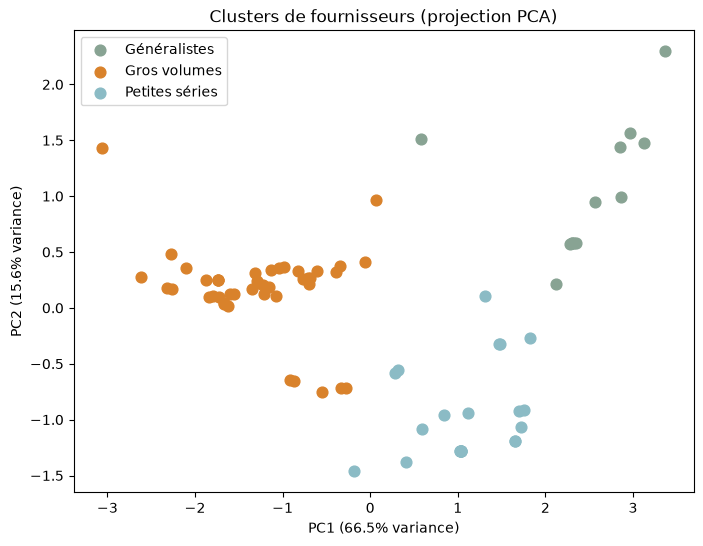

In [22]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

noms_clusters = {0: "Généralistes", 1: "Gros volumes", 2: "Petites séries"}

# Mêmes couleurs que dans le dashboard Power BI
# Mêmes couleurs que dans le dashboard Power BI
couleurs = {
    "Généralistes": "#88A393",
    "Gros volumes": "#D9822B",
    "Petites séries": "#8BBBC5",
}

plt.figure(figsize=(8, 6))
for cl, nom in noms_clusters.items():
    masque = vendor_df["cluster"] == cl
    plt.scatter(X_pca[masque, 0], X_pca[masque, 1],
                label=nom, color=couleurs[nom], s=60)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.title("Clusters de fournisseurs (projection PCA)")
plt.legend()
plt.savefig("outputs/clusters_pca.png")
plt.show()

## 5 bis. Segmentation complète des 104 fournisseurs

Le K-Means ne porte que sur les 79 fournisseurs ayant au moins 30 lignes d'achat. On complète avec deux segments définis par règle métier :
- **Sans commande** : aucune ligne d'achat ;
- **Historique insuffisant** : moins de 30 lignes, taux de rejet peu fiable.

In [18]:
# Tous les fournisseurs du référentiel, avec leur nombre de lignes d'achat (0 si aucune commande)
conn = sqlite3.connect("../database/adventureworks.db")
all_vendors = pd.read_sql("""
SELECT v.businessentityid AS vendorid,
       v.name,
       COUNT(pod.purchaseorderdetailid) AS nb_lignes
FROM vendor v
LEFT JOIN purchaseorderheader poh ON poh.vendorid = v.businessentityid
LEFT JOIN purchaseorderdetail pod ON pod.purchaseorderid = poh.purchaseorderid
GROUP BY v.businessentityid, v.name
""", conn)
conn.close()

# Noms des clusters, d'après le tableau de profils (section 4)
noms_clusters = {0: "Généralistes", 1: "Gros volumes", 2: "Petites séries"}
vendor_df["segment"] = vendor_df["cluster"].map(noms_clusters)

# Segment K-Means pour les 79 fournisseurs(fournisseurs actifs - fournisseurs peu de commande)clusterisés, règle métier pour les autres
all_vendors = all_vendors.merge(vendor_df[["vendorid", "segment"]], on="vendorid", how="left")
all_vendors.loc[all_vendors["nb_lignes"] == 0, "segment"] = "Sans commande"
all_vendors.loc[(all_vendors["nb_lignes"] > 0) & (all_vendors["nb_lignes"] < 30), "segment"] = "Peu d'historique"

print(all_vendors.shape)
all_vendors["segment"].value_counts()

(104, 4)


segment
Gros volumes        44
Petites séries      22
Sans commande       18
Généralistes        13
Peu d'historique     7
Name: count, dtype: int64

## 6. Export du résultat

In [19]:
vendor_df.to_csv("outputs/vendor_clusters.csv", index=False, sep=";")
vendor_df.head(20)

,vendorid,total_orders,avg_reject_rate,avg_receipt_rate,avg_order_qty,product_diversity,cluster,segment
0,1510,51,0.058824,1.000000,3.0,1,2,Petites séries
1,1664,51,0.053832,0.982460,550.0,1,1,Gros volumes
2,1588,100,0.053455,0.990091,550.0,2,1,Gros volumes
3,1560,102,0.052888,0.992228,550.0,2,1,Gros volumes
4,1658,102,0.052888,0.991747,550.0,2,1,Gros volumes
5,1586,100,0.052455,0.991582,550.0,2,1,Gros volumes
6,1576,100,0.051964,0.990091,550.0,2,1,Gros volumes
7,1682,50,0.051927,0.985091,550.0,1,1,Gros volumes
8,1590,100,0.050984,0.989544,1250.0,2,1,Gros volumes
9,1620,51,0.050909,0.985383,550.0,1,1,Gros volumes


In [20]:
# Export de la segmentation complète pour Power BI, au même endroit que les autres tables
chemin = "../parquet_for_powerbi/vendor_segments.parquet"
all_vendors.to_parquet(chemin, index=False)

# Vérification : on relit le fichier exporté
verif = pd.read_parquet(chemin)
print(f"Fichier exporté : {chemin}")
print(f"{verif.shape[0]} fournisseurs, {verif.shape[1]} colonnes : {list(verif.columns)}")
verif["segment"].value_counts()

Fichier exporté : ../parquet_for_powerbi/vendor_segments.parquet
104 fournisseurs, 4 colonnes : ['vendorid', 'name', 'nb_lignes', 'segment']


segment
Gros volumes        44
Petites séries      22
Sans commande       18
Généralistes        13
Peu d'historique     7
Name: count, dtype: int64